# 05 - Final test evaluation
Score the chosen model (`cnn-sqrt`) **once** on `mitbih_test.csv`. Nothing is trained or tuned here.
Do not change the model or settings based on this result.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import mlflow
import mlflow.pytorch
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from torch.utils.data import DataLoader, TensorDataset

CLASS_NAMES = ["Normal", "Supraventricular", "Ventricular", "Fusion", "Unknown"]
MODEL_RUN_NAME = "cnn-sqrt"

mlflow.set_tracking_uri(f"sqlite:///{(Path.cwd().parent / 'mlflow.db').as_posix()}")
mlflow.set_experiment("ecg-arrhythmia")

2026/10/17 16:57:01 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at C:\Users\Sangeeta\anaconda3\envs\ecg\Lib\site-packages\mlflow\assistant\skills\instrumenting-with-mlflow-tracing\SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


<Experiment: artifact_location='file:///c:/Users/Sangeeta/OneDrive/Desktop/ecg-arrhythmia-detection/notebooks/mlruns/1', creation_time=1791903145630, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1791903145630, lifecycle_stage='active', name='ecg-arrhythmia', tags={}, trace_location=None, workspace='default'>

## Load the chosen model from MLflow
Latest finished run named `cnn-sqrt`; its model was saved with the best-epoch weights.

In [2]:
runs = mlflow.search_runs(
    experiment_names=["ecg-arrhythmia"],
    filter_string=f"tags.mlflow.runName = '{MODEL_RUN_NAME}' and attributes.status = 'FINISHED'",
    order_by=["attributes.start_time DESC"],
)
source_run = runs.iloc[0]
print("model run:", source_run["run_id"])
print("validation macro-F1 of that run:", round(source_run["metrics.final_val_macro_f1"], 4))

model = mlflow.pytorch.load_model(f"runs:/{source_run['run_id']}/model")
model.eval()

model run: 0a1f55264ff54341a0362b27c000512e
validation macro-F1 of that run: 0.9111


CNN(
  (features): Sequential(
    (0): Conv1d(1, 32, kernel_size=(5,), stride=(1,), padding=(2,))
    (1): ReLU()
    (2): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv1d(32, 64, kernel_size=(5,), stride=(1,), padding=(2,))
    (4): ReLU()
    (5): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv1d(64, 128, kernel_size=(3,), stride=(1,), padding=(1,))
    (7): ReLU()
    (8): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.3, inplace=False)
    (2): Linear(in_features=2944, out_features=64, bias=True)
    (3): ReLU()
    (4): Dropout(p=0.3, inplace=False)
    (5): Linear(in_features=64, out_features=5, bias=True)
  )
)

## Load the test set
Same format as the training file: columns 0-186 are the signal, column 187 is the label.

In [3]:
test_df = pd.read_csv("../data/mitbih_test.csv", header=None)
X_test = test_df.iloc[:, :187].values             # (N_test, 187)
y_test = test_df.iloc[:, 187].values.astype(int)  # (N_test,)
print(X_test.shape, y_test.shape)
print("signal min/max:", X_test.min(), X_test.max())
print("label counts:", np.bincount(y_test))

test_loader = DataLoader(
    TensorDataset(
        torch.tensor(X_test, dtype=torch.float32),  # (N_test, 187)
        torch.tensor(y_test, dtype=torch.long),     # (N_test,)
    ),
    batch_size=256,
    shuffle=False,
)

(21892, 187) (21892,)
signal min/max: 0.0 1.0
label counts: [18118   556  1448   162  1608]


## Predict (no training, no gradients)

In [4]:
all_preds = []
with torch.no_grad():
    for xb, yb in test_loader:                # xb (B, 187)
        logits = model(xb)                    # (B, 5)
        all_preds.append(logits.argmax(dim=1))  # (B,)
test_preds = torch.cat(all_preds).numpy()     # (N_test,)

test_f1 = f1_score(y_test, test_preds, average="macro")
report = classification_report(y_test, test_preds, target_names=CLASS_NAMES, digits=4)
print(report)
print("Test macro-F1:", round(test_f1, 4))

                  precision    recall  f1-score   support

          Normal     0.9918    0.9882    0.9900     18118
Supraventricular     0.7740    0.8255    0.7990       556
     Ventricular     0.9535    0.9496    0.9516      1448
          Fusion     0.7841    0.8519    0.8166       162
         Unknown     0.9773    0.9894    0.9833      1608

        accuracy                         0.9806     21892
       macro avg     0.8961    0.9209    0.9081     21892
    weighted avg     0.9811    0.9806    0.9808     21892

Test macro-F1: 0.9081


## Log the result to MLflow
Saved as a separate run so the validation runs stay untouched.

In [5]:
with mlflow.start_run(run_name=f"{MODEL_RUN_NAME}-test"):
    mlflow.log_param("source_run_id", source_run["run_id"])
    mlflow.log_param("test_file", "mitbih_test.csv")
    mlflow.log_metric("test_macro_f1", test_f1)
    mlflow.log_metric("test_accuracy", float((test_preds == y_test).mean()))
    mlflow.log_text(report, "test_classification_report.txt")

## Confusion matrix

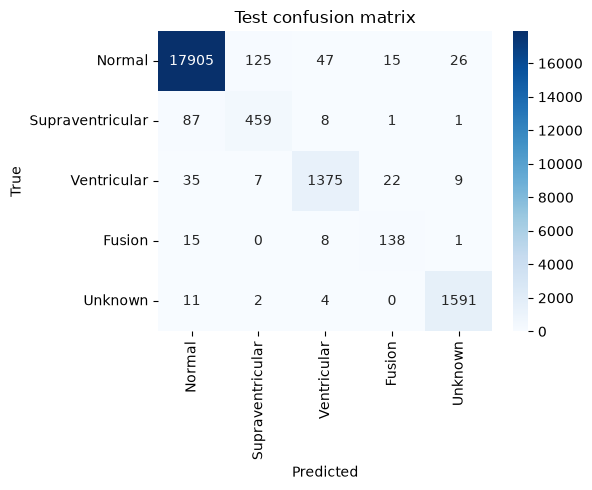

In [6]:
cm = confusion_matrix(y_test, test_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Test confusion matrix")
plt.tight_layout()
plt.show()